# 07 - Logistic Regression

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and test Logistic Regression on the processed PhiUSIIL data (Experiment 1), compare different feature sets, and test the URL-only version on the external dataset (Experiment 2).

**About the model:** Logistic Regression gives each feature a weight. It adds up the weighted features and turns the total into a probability between 0 and 1. If the probability is above 0.5, the URL is called phishing. It is a simple and fast model, and it is a good baseline to compare the other models with. It needs scaling, so we use the shared scaling pipeline.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`, `results/feature_importance/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

sys.path.append(str(Path("..").resolve()))
from src.data import get_feature_sets, load_train_test, load_url_experiment, sample_rows
from src.features import extract_url_features
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_by_source,
    cross_validate_model,
    evaluate_model,
    evaluate_predictions,
    fit_with_weights,
    get_scores,
    make_cv,
    make_sample_weights,
    make_scaled_pipeline,
    plot_confusion_matrix,
    save_results,
    tune_cutoff_by_source,
    tune_by_source,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 187,363 rows | 69 features
Test set:     46,841 rows | 69 features


## Model Settings

`C` controls how strict the model is. A small `C` keeps the weights small and the model simple. A large `C` lets the model follow the training data more closely. We try 4 values. Logistic Regression is fast, so we tune on the full training set.

In [3]:
MODEL_NAME = "Logistic Regression"
model = make_scaled_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10],
}

TUNING_SAMPLE_SIZE = None

## 1. Hyperparameter Tuning

We try each combination of settings in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'logisticregression__C': 10}
Best cross-validation F1: 0.9999


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [5]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,0.9999,0.0000
Precision,1.0000,0.0000
Recall,0.9998,0.0001
F1,0.9999,0.0001
ROC-AUC,1.0000,0.0000


### Learning Curve

A learning curve shows how the score changes when the model gets more training data. We use the best settings from tuning and 5-fold cross-validation on a sample of 50,000 training rows.

- **Training F1:** the score on the data the model was trained on.
- **Validation F1:** the score on data the model did not see.

How we read it (at the last point):

- **Overfitting:** the gap (training F1 − validation F1) is more than 0.01. The model memorises the training data.
- **Underfitting:** validation F1 is below 0.95 and the gap is small. The model is too simple to learn the pattern.
- **Good fit:** both lines are high and close together.

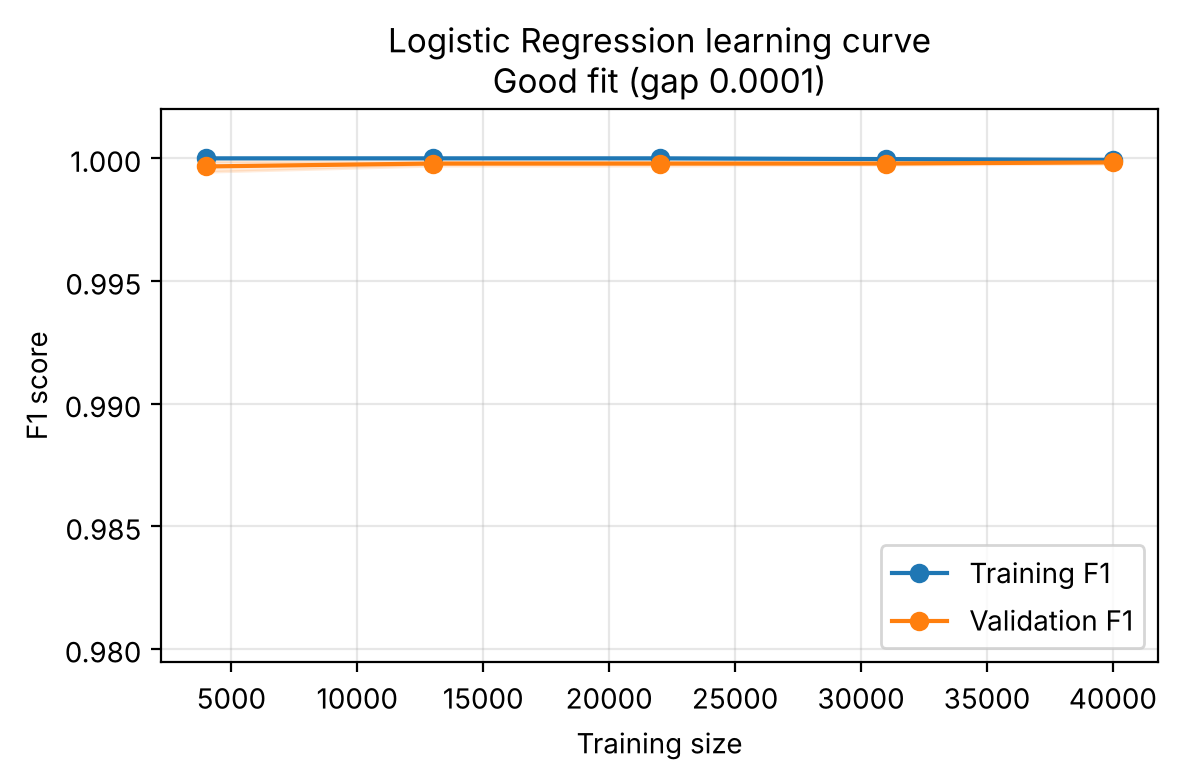

Result: Good fit (gap 0.0001)


,Training size,Training F1,Training Std,Validation F1,Validation Std
0,4000,1.0000,0.0,0.9997,0.0002
1,13000,1.0000,0.0,0.9998,0.0001
2,22000,1.0000,0.0,0.9998,0.0001
3,31000,1.0000,0.0,0.9998,0.0000
4,40000,0.9999,0.0,0.9998,0.0001


In [ ]:
from src.evaluation import describe_fit, learning_curve_table, plot_learning_curve

X_curve, y_curve = sample_rows(X_train, y_train, 50000)
curve = learning_curve_table(best_model, X_curve, y_curve)
plot_learning_curve(curve, f"{MODEL_NAME} learning curve")

fit, gap = describe_fit(curve)
print(f"Result: {fit} (gap {gap:.4f})")
curve.round(4)

**Result: Good fit.**

- Training F1 is 0.9999 and validation F1 is 0.9998 at the last point, so the gap is only 0.0001.
- Both lines are high and very close together.
- So Logistic Regression is not overfitting and not underfitting. A simple linear model is enough for this data.

## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [6]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 0.4 seconds


,Test Score
Accuracy,1.0000
Precision,1.0000
Recall,0.9999
F1,0.9999
ROC-AUC,1.0000


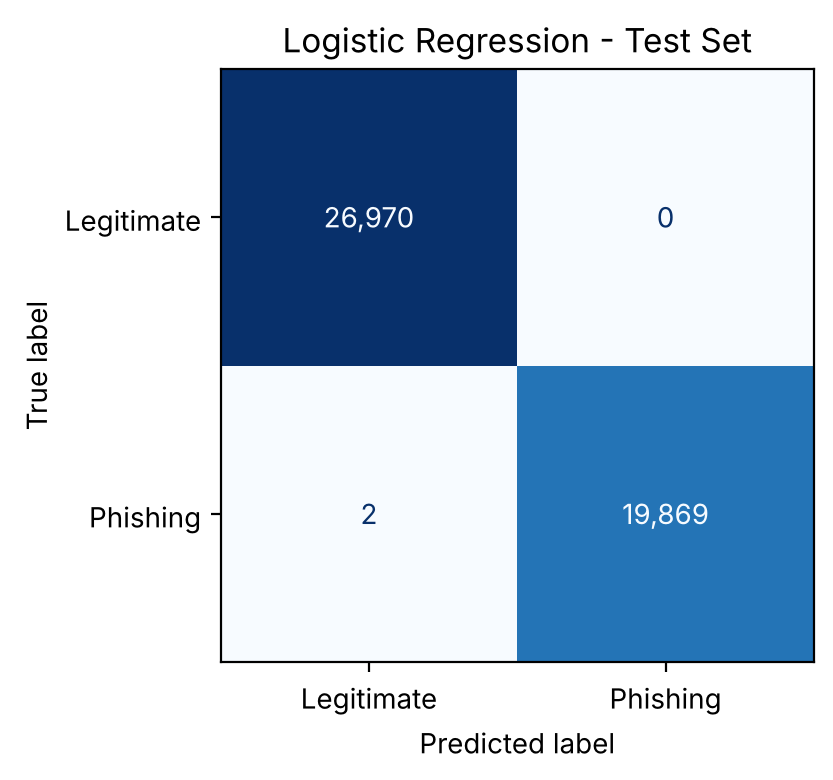

In [7]:
plot_confusion_matrix(y_test, final_model.predict(X_test), f"{MODEL_NAME} - Test Set")

### Feature Weights

Logistic Regression gives each feature a weight. A positive weight pushes a URL towards phishing, and a negative weight pushes it towards legitimate. Because all features are scaled, we can compare the size of the weights. We show the 15 features with the biggest weights.

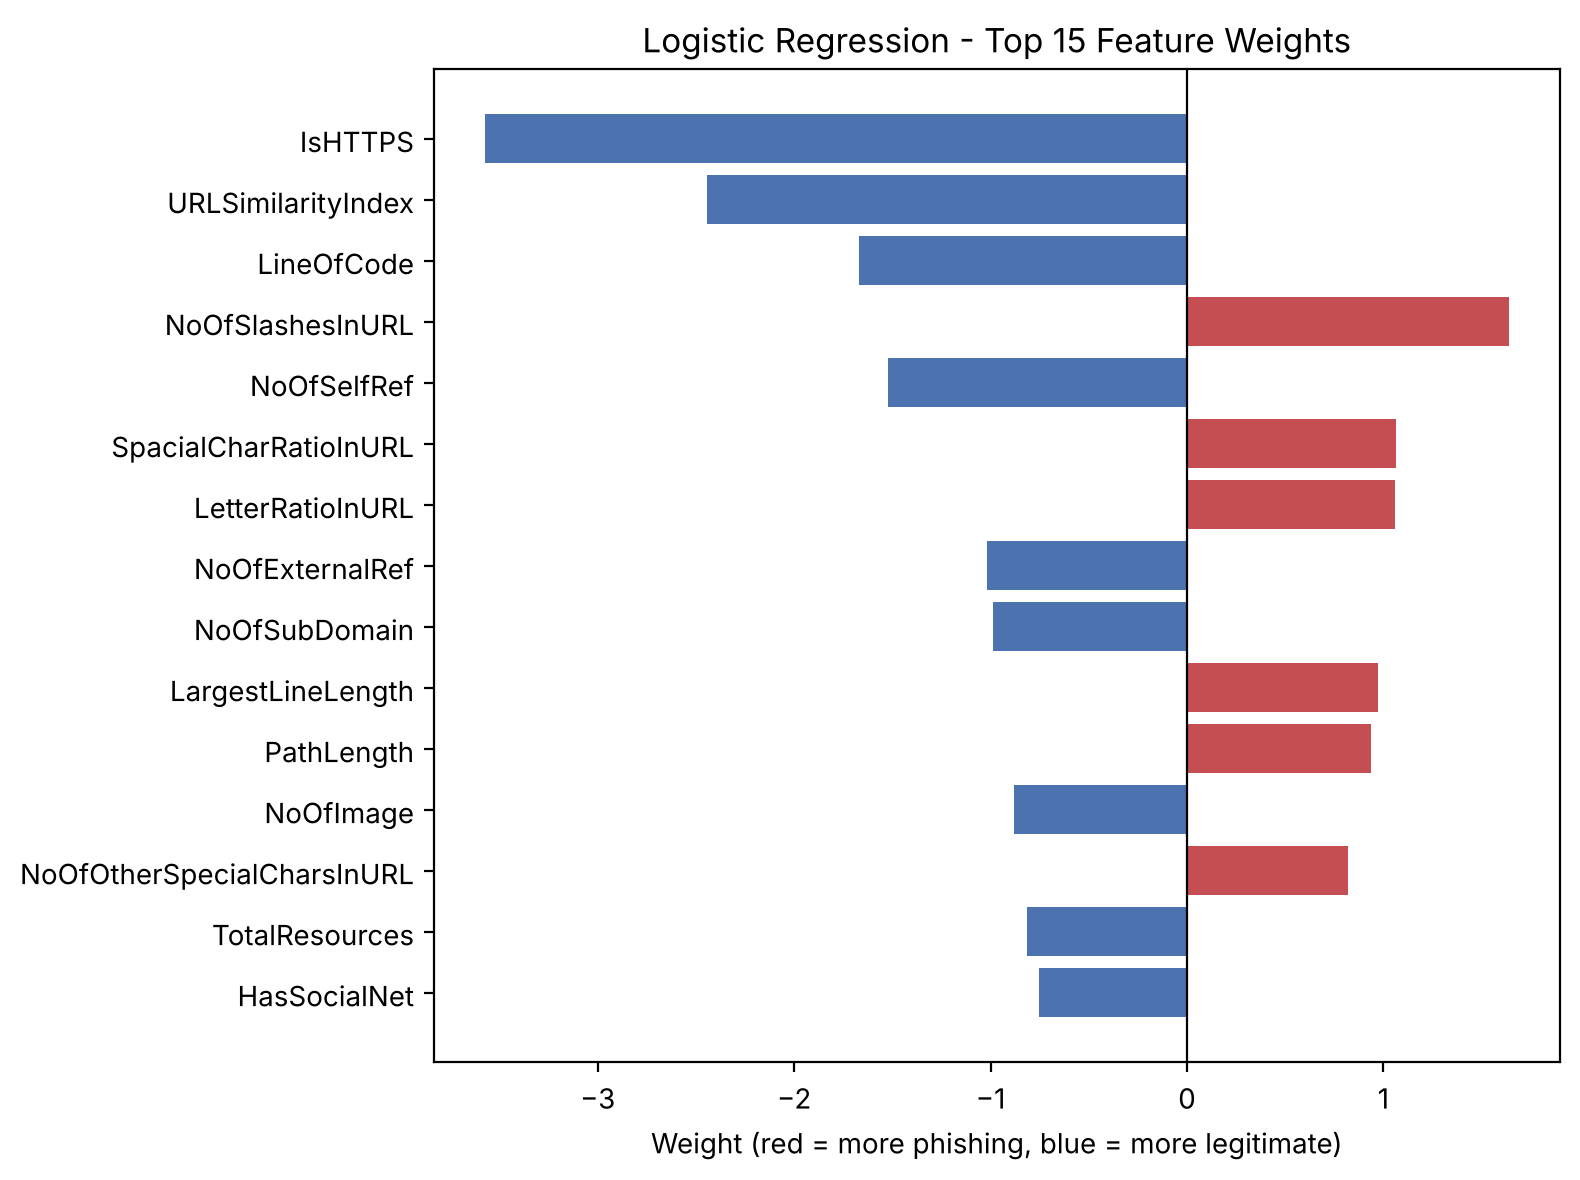

,Weight
IsHTTPS,-3.5752
URLSimilarityIndex,-2.4411
LineOfCode,-1.6703
NoOfSlashesInURL,1.6385
NoOfSelfRef,-1.5228
SpacialCharRatioInURL,1.0640
LetterRatioInURL,1.0605
NoOfExternalRef,-1.0197
NoOfSubDomain,-0.9853
LargestLineLength,0.9710


In [8]:
weights = pd.Series(final_model[-1].coef_[0], index=X_train.columns)
top_features = weights.reindex(weights.abs().sort_values(ascending=False).index).head(15)
colors = ["#C44E52" if w > 0 else "#4C72B0" for w in top_features.values[::-1]]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_features.index[::-1], top_features.values[::-1], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"{MODEL_NAME} - Top 15 Feature Weights")
ax.set_xlabel("Weight (red = more phishing, blue = more legitimate)")
fig.tight_layout()

save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / "logistic_regression_feature_importance.png", dpi=300)
plt.show()

top_features.round(4).to_frame("Weight")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [9]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,1.0,1.0,0.9999,0.9999,1.0
Original features only,1.0,1.0,0.9999,0.9999,1.0
Without URLSimilarityIndex,1.0,1.0,0.9999,0.9999,1.0


## 5. Experiment 2: URL Features Only

In real use, DetectIt only gets a URL, not the HTML of the page. So here the model only uses the **40 URL features** that we can create from any URL (18 from `02_preprocessing.ipynb` and 22 new ones from `03_external_dataset.ipynb`).

In the first version of this experiment, we trained only on PhiUSIIL, and every model scored about 50% on the Kaggle dataset, because the legitimate URLs in the two datasets look very different. Now we train on **both datasets**:

- **Training set:** PhiUSIIL training set (80%) + Kaggle training part (80%)
- **Test sets:** PhiUSIIL test set (20%) and Kaggle test part (20%). We test on them **separately**. The PhiUSIIL test set is about 21 times bigger, so one combined score would mostly show the PhiUSIIL score and hide how the model does on Kaggle URLs.

No URL is in both a training set and a test set (checked in `02_preprocessing.ipynb` and `03_external_dataset.ipynb`).

In [10]:
X_url_train, y_url_train, url_source, url_test_sets = load_url_experiment()

print(f"Training set: {X_url_train.shape[0]:,} rows | {X_url_train.shape[1]} features")
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    print(f"{test_name}: {X_url_test.shape[0]:,} rows")

Training set: 196,230 rows | 40 features
PhiUSIIL test set: 46,841 rows
Kaggle test set: 2,217 rows


### Sample Weights

The training set has about 21 times more PhiUSIIL URLs than Kaggle URLs. Without help, the model would mostly learn PhiUSIIL patterns and almost ignore the Kaggle URLs. So we give each Kaggle URL a bigger **sample weight**. A weight of 21 means the model treats one mistake on that URL like 21 mistakes, so both datasets matter equally during training.

In [11]:
url_weights = make_sample_weights(url_source)

pd.DataFrame({
    "Training URLs": url_source.value_counts(),
    "Weight per URL": pd.Series(url_weights, index=url_source).groupby(level=0).first(),
}).round(2)

,Training URLs,Weight per URL
Source,,
Kaggle,8867,21.13
PhiUSIIL,187363,1.00


### Hyperparameter Tuning

The best setting from Section 1 was chosen for 69 features on PhiUSIIL only. Experiment 2 uses different features and more varied data, so we tune again. For every value of `C` below, we run 3-fold cross-validation on the training set (with sample weights) and calculate the F1-score separately for PhiUSIIL URLs and Kaggle URLs. We keep the value with the highest **average of the two F1-scores**, so the model works well on both datasets, not just on the bigger one. The test sets are not used here.

We try a wider range of `C` than in Section 1 (from 0.01 to 100). Logistic Regression is fast, so we tune on the full training set.

In [12]:
url_param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100],
}

X_url_tune, y_url_tune, url_source_tune = X_url_train, y_url_train, url_source

url_tuning, url_best_params = tune_by_source(model, url_param_grid, X_url_tune, y_url_tune, url_source_tune)
url_best_model = clone(model).set_params(**url_best_params)

print(f"Best settings: {url_best_params}")
url_tuning.round(4)

Best settings: {'logisticregression__C': 10}


,logisticregression__C,PhiUSIIL F1,Kaggle F1,Mean F1
0,10.0,0.8452,0.8362,0.8407
1,1.0,0.8452,0.8358,0.8405
2,100.0,0.8451,0.8358,0.8405
3,0.1,0.8448,0.8358,0.8403
4,0.01,0.8435,0.8342,0.8389


### Cross-Validation

We check the best settings with 5-fold cross-validation and calculate the scores for PhiUSIIL URLs and Kaggle URLs separately. The Kaggle scores here are used to choose the best model for Experiment 2. The test sets are only used to report the final scores.

In [13]:
url_cv_results = cross_validate_by_source(url_best_model, X_url_tune, y_url_tune, url_source_tune)
url_cv_results.round(4)

,PhiUSIIL Mean,PhiUSIIL Std,Kaggle Mean,Kaggle Std
Accuracy,0.8853,0.0016,0.8290,0.0153
Precision,0.9886,0.0009,0.7975,0.0172
Recall,0.7382,0.0039,0.8782,0.0118
F1,0.8452,0.0025,0.8359,0.0140
ROC-AUC,0.9867,0.0005,0.9193,0.0061


### Final Test

We train two models with the best settings and test both of them on both test sets:

- **Trained on PhiUSIIL only:** the first version of this experiment, with the 40 URL features.
- **Trained on both datasets:** the new version, with sample weights.

Comparing the two shows how much adding Kaggle URLs to the training set helps.

In [14]:
phiusiil_only = (url_source == "PhiUSIIL").to_numpy()

start = time.perf_counter()
url_model = fit_with_weights(clone(url_best_model), X_url_train, y_url_train, url_weights)
url_train_time = time.perf_counter() - start

url_models = {
    "Trained on PhiUSIIL only": clone(url_best_model).fit(X_url_train[phiusiil_only], y_url_train[phiusiil_only]),
    "Trained on both datasets": url_model,
}

url_results = {}
for train_name, model_version in url_models.items():
    for test_name, (X_url_test, y_url_test) in url_test_sets.items():
        url_results[(train_name, test_name)] = evaluate_model(model_version, X_url_test, y_url_test)

print(f"Training time (both datasets): {url_train_time:.1f} seconds")
pd.DataFrame(url_results).T.round(4)

Training time (both datasets): 1.8 seconds


Accuracy  Precision  Recall  \
Trained on PhiUSIIL only PhiUSIIL test set    0.9981     0.9998  0.9957   
                         Kaggle test set      0.4948     0.4952  0.9927   
Trained on both datasets PhiUSIIL test set    0.8881     0.9881  0.7453   
                         Kaggle test set      0.8223     0.7960  0.8626   

                                                F1  ROC-AUC  
Trained on PhiUSIIL only PhiUSIIL test set  0.9978   0.9990  
                         Kaggle test set    0.6608   0.7106  
Trained on both datasets PhiUSIIL test set  0.8497   0.9866  
                         Kaggle test set    0.8279   0.9100

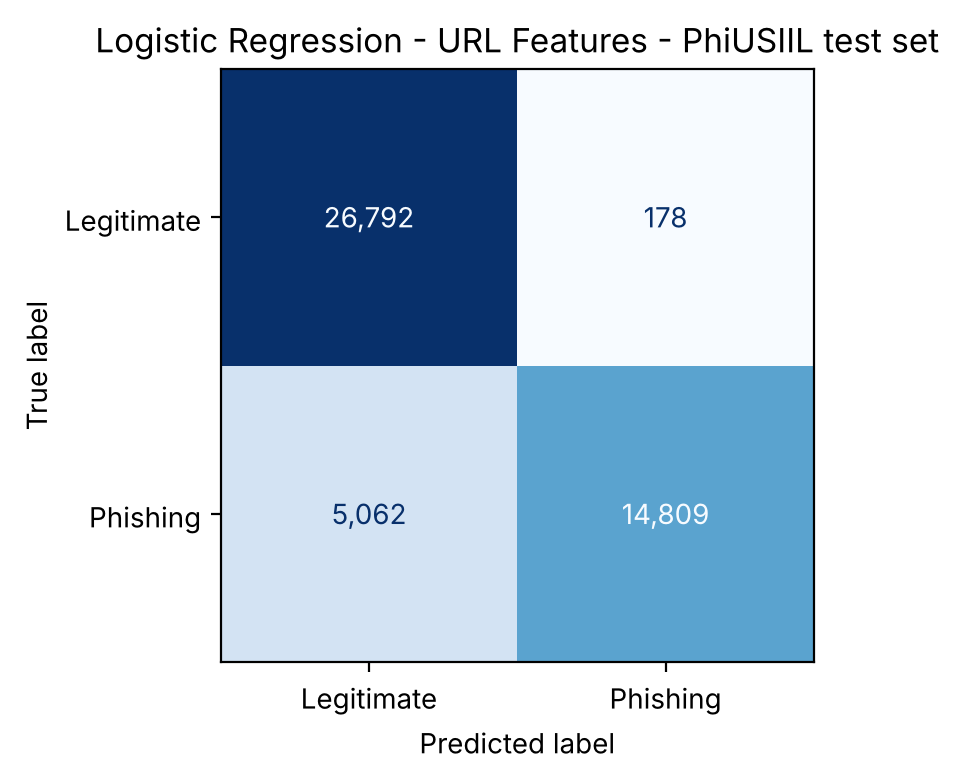

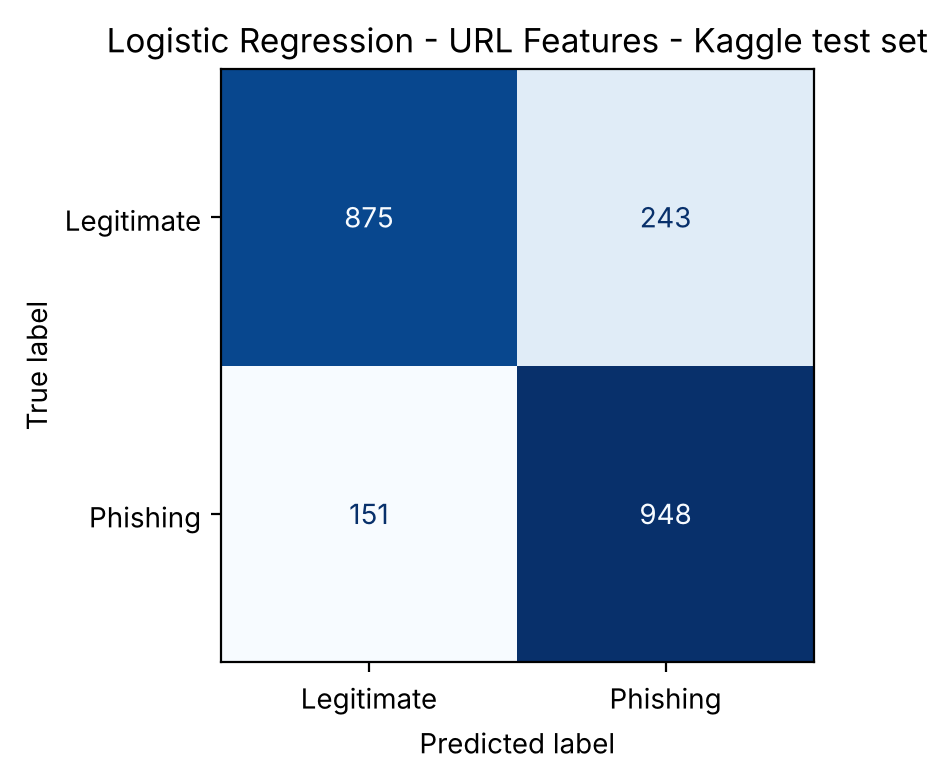

In [15]:
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    plot_confusion_matrix(y_url_test, url_model.predict(X_url_test), f"{MODEL_NAME} - URL Features - {test_name}")

### Choosing the Cut-off

By default, a URL is called phishing when the model gives it a probability of 0.5 or more. The sample weights make Kaggle URLs count much more during training, which moves the probabilities, so 0.5 may not be the best place to cut for both datasets.

We choose the cut-off without touching the test sets. With 5-fold cross-validation, every training URL gets a probability from a model that did not see it during training (*out-of-fold* predictions). For each cut-off from 0.05 to 0.95, we calculate the F1-score for PhiUSIIL URLs and Kaggle URLs, and keep the cut-off with the highest average. We then apply it to the test sets once.

In [16]:
cutoff_table, best_cutoff = tune_cutoff_by_source(url_best_model, X_url_train, y_url_train, url_source)

print(f"Best cut-off: {best_cutoff:.2f}")
cutoff_table.round(4)

Best cut-off: 0.25


,Cut-off,PhiUSIIL F1,Kaggle F1,Mean F1
0,0.05,0.6301,0.7415,0.6858
1,0.10,0.8622,0.7710,0.8166
2,0.15,0.9372,0.7844,0.8608
3,0.20,0.9531,0.8012,0.8772
4,0.25,0.9534,0.8195,0.8864
5,0.30,0.9377,0.8300,0.8839
6,0.35,0.9104,0.8347,0.8725
7,0.40,0.8847,0.8369,0.8608
8,0.45,0.8630,0.8367,0.8499
9,0.50,0.8452,0.8358,0.8405


In [17]:
cutoff_results = {}
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    test_scores = get_scores(url_model, X_url_test)
    cutoff_results[("Cut-off 0.5", test_name)] = url_results[("Trained on both datasets", test_name)]
    cutoff_results[(f"Cut-off {best_cutoff:.2f}", test_name)] = evaluate_predictions(y_url_test, (test_scores >= best_cutoff).astype(int), test_scores)

pd.DataFrame(cutoff_results).T.round(4)

,,Accuracy,Precision,Recall,F1,ROC-AUC
Cut-off 0.5,PhiUSIIL test set,0.8881,0.9881,0.7453,0.8497,0.9866
Cut-off 0.25,PhiUSIIL test set,0.9609,0.9482,0.9603,0.9542,0.9866
Cut-off 0.5,Kaggle test set,0.8223,0.7960,0.8626,0.8279,0.9100
Cut-off 0.25,Kaggle test set,0.7785,0.7071,0.9445,0.8087,0.9100


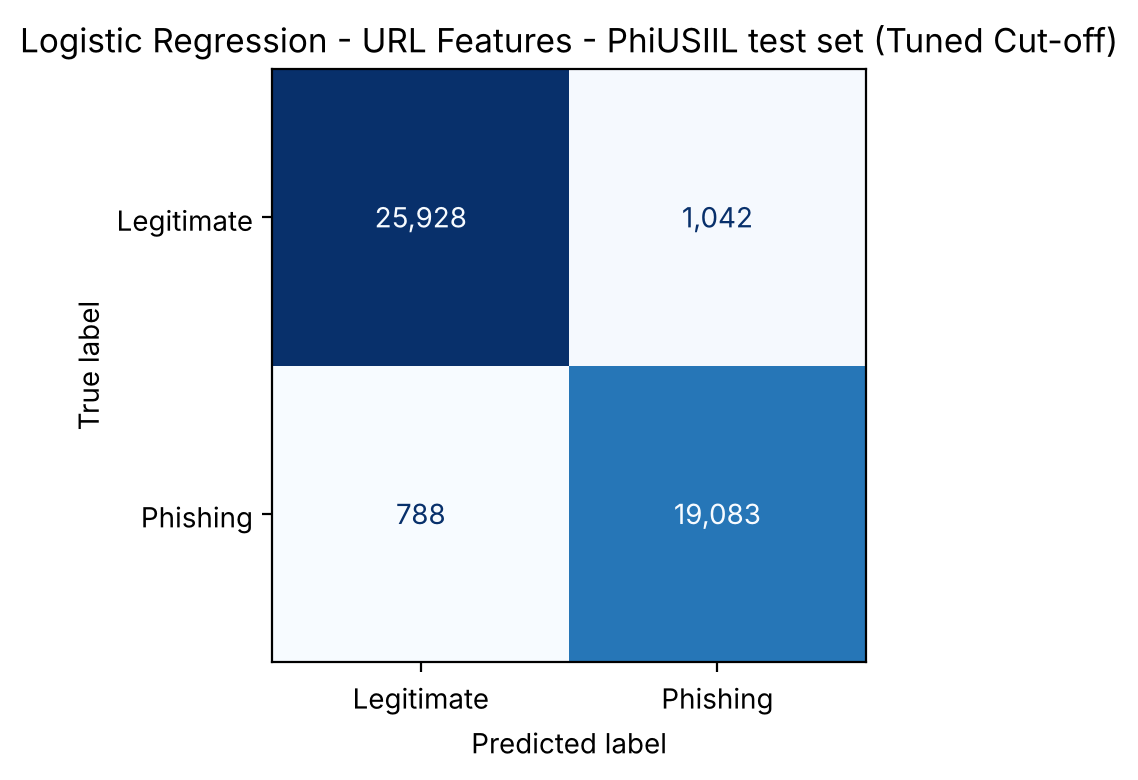

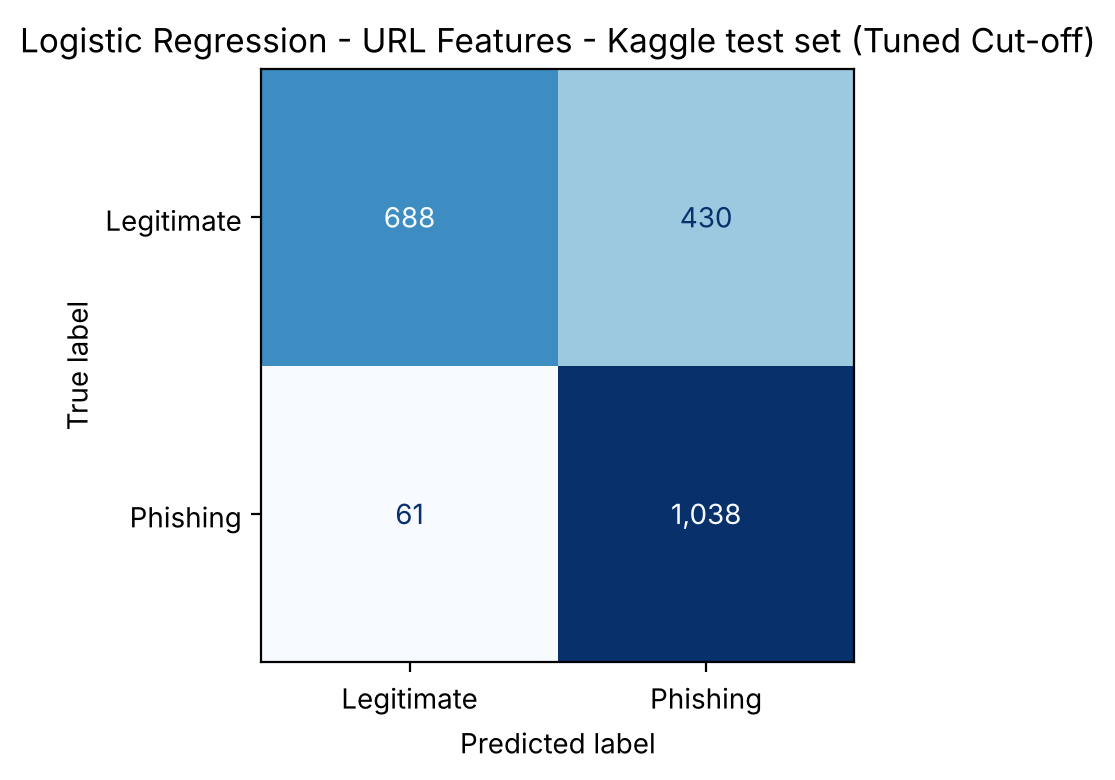

In [18]:
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    tuned_pred = (get_scores(url_model, X_url_test) >= best_cutoff).astype(int)
    plot_confusion_matrix(y_url_test, tuned_pred, f"{MODEL_NAME} - URL Features - {test_name} (Tuned Cut-off)")

### Did the 22 New URL Features Help?

We train the same model on both datasets again, but only with the 18 URL features from `02_preprocessing.ipynb`, and compare it with the model that uses all 40 URL features.

In [19]:
base_url_features = list(extract_url_features("example.com"))
base_url_model = fit_with_weights(clone(url_best_model), X_url_train[base_url_features], y_url_train, url_weights)

url_feature_results = {}
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    url_feature_results[("18 URL features", test_name)] = evaluate_model(base_url_model, X_url_test[base_url_features], y_url_test)
    url_feature_results[("40 URL features", test_name)] = url_results[("Trained on both datasets", test_name)]

pd.DataFrame(url_feature_results).T.round(4)

,,Accuracy,Precision,Recall,F1,ROC-AUC
18 URL features,PhiUSIIL test set,0.8218,0.9682,0.5998,0.7407,0.9596
40 URL features,PhiUSIIL test set,0.8881,0.9881,0.7453,0.8497,0.9866
18 URL features,Kaggle test set,0.7397,0.7098,0.8035,0.7537,0.8452
40 URL features,Kaggle test set,0.8223,0.7960,0.8626,0.8279,0.9100


### Feature Weights

We show the 15 URL features with the biggest weights in the final Experiment 2 model. A positive weight pushes a URL towards phishing, and a negative weight pushes it towards legitimate.

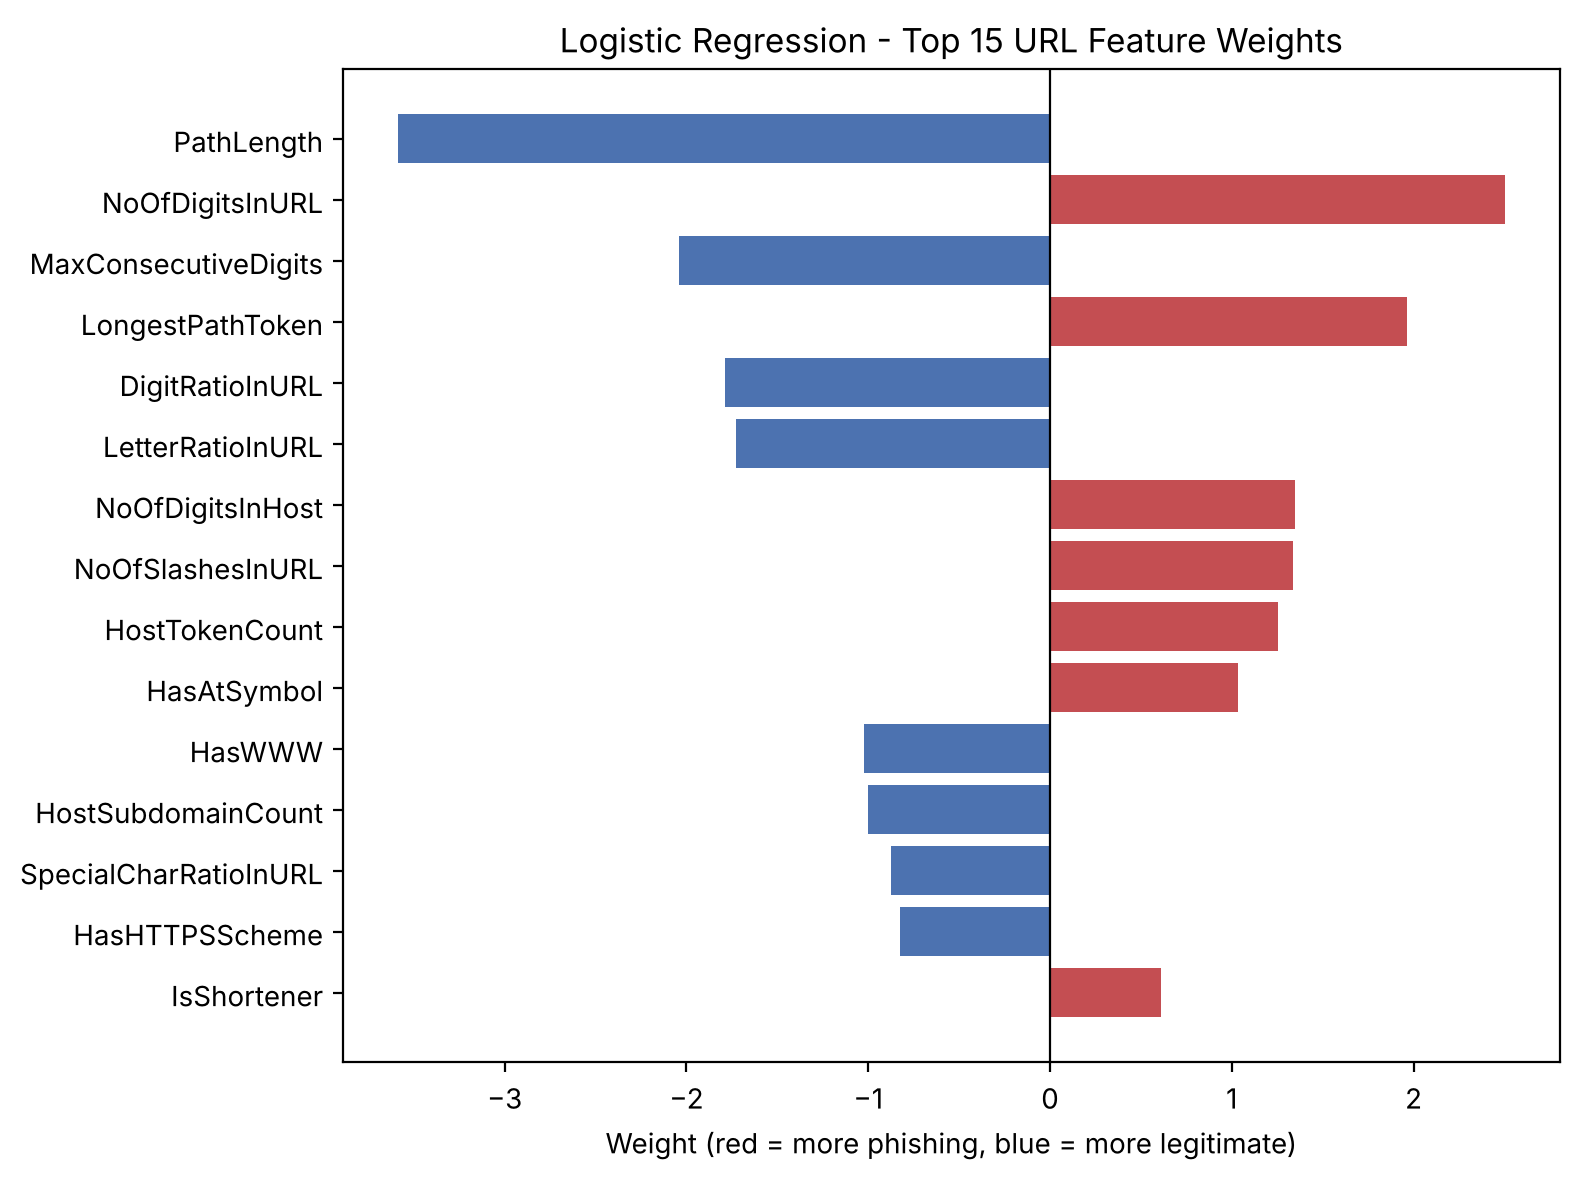

,Weight
PathLength,-3.5874
NoOfDigitsInURL,2.5014
MaxConsecutiveDigits,-2.0434
LongestPathToken,1.9626
DigitRatioInURL,-1.7878
LetterRatioInURL,-1.7289
NoOfDigitsInHost,1.3500
NoOfSlashesInURL,1.3353
HostTokenCount,1.2527
HasAtSymbol,1.0367


In [20]:
url_weights_table = pd.Series(url_model[-1].coef_[0], index=X_url_train.columns)
top_url_features = url_weights_table.reindex(url_weights_table.abs().sort_values(ascending=False).index).head(15)
colors = ["#C44E52" if w > 0 else "#4C72B0" for w in top_url_features.values[::-1]]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_url_features.index[::-1], top_url_features.values[::-1], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"{MODEL_NAME} - Top 15 URL Feature Weights")
ax.set_xlabel("Weight (red = more phishing, blue = more legitimate)")
fig.tight_layout()

save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / "logistic_regression_url_feature_importance.png", dpi=300)
plt.show()

top_url_features.round(4).to_frame("Weight")

### Does the Model Depend on `www` and HTTPS?

In PhiUSIIL, every legitimate URL starts with `www` and uses HTTPS. So a model may learn that a URL without `www` or HTTPS is suspicious, and a legitimate website without them might get a false alarm.

To check how much the model depends on this, we remove `http://`, `https://` and `www.` from every URL before creating the features. This removes `HasWWW` and `HasHTTPSScheme`, and also removes this information from the other features (for example, `FullURLLength` no longer counts `https://www.`). We then train the same model with the same settings on both datasets and compare the scores.

In [21]:
X_clean_train, _, _, clean_test_sets = load_url_experiment(clean_urls=True)
clean_model = fit_with_weights(clone(url_best_model), X_clean_train, y_url_train, url_weights)

clean_results = {}
for test_name, (X_clean_test, y_clean_test) in clean_test_sets.items():
    clean_results[("With www and HTTPS", test_name)] = url_results[("Trained on both datasets", test_name)]
    clean_results[("Without www and HTTPS", test_name)] = evaluate_model(clean_model, X_clean_test, y_clean_test)

print(f"Features without www and HTTPS: {X_clean_train.shape[1]}")
pd.DataFrame(clean_results).T.round(4)

Features without www and HTTPS: 38


,,Accuracy,Precision,Recall,F1,ROC-AUC
With www and HTTPS,PhiUSIIL test set,0.8881,0.9881,0.7453,0.8497,0.9866
Without www and HTTPS,PhiUSIIL test set,0.8464,0.9417,0.6799,0.7897,0.8854
With www and HTTPS,Kaggle test set,0.8223,0.7960,0.8626,0.8279,0.9100
Without www and HTTPS,Kaggle test set,0.8151,0.8187,0.8053,0.8119,0.8995


## 6. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [22]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
    {"Experiment": "URL features - Cross-validation - PhiUSIIL", **url_cv_results["PhiUSIIL Mean"].to_dict()},
    {"Experiment": "URL features - Cross-validation - Kaggle", **url_cv_results["Kaggle Mean"].to_dict()},
]

for (train_name, test_name), scores in url_results.items():
    row = {"Experiment": f"URL features - {train_name} - {test_name}", **scores}
    if train_name == "Trained on both datasets" and test_name == "PhiUSIIL test set":
        row["Train Time (s)"] = url_train_time
    results.append(row)

for (feature_name, test_name), scores in url_feature_results.items():
    if feature_name == "18 URL features":
        results.append({"Experiment": f"URL features - Trained on both datasets (18 URL features) - {test_name}", **scores})

for (version, test_name), scores in clean_results.items():
    if version == "Without www and HTTPS":
        results.append({"Experiment": f"URL features - Trained on both datasets (without www and HTTPS) - {test_name}", **scores})

for (version, test_name), scores in cutoff_results.items():
    if version != "Cut-off 0.5":
        results.append({"Experiment": f"URL features - Trained on both datasets (cut-off {best_cutoff:.2f}) - {test_name}", **scores})

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,Logistic Regression,Cross-validation,0.9999,1.0000,0.9998,0.9999,1.0000,NaN
1,Logistic Regression,Test set - All features,1.0000,1.0000,0.9999,0.9999,1.0000,0.4447
2,Logistic Regression,Test set - Original features only,1.0000,1.0000,0.9999,0.9999,1.0000,NaN
3,Logistic Regression,Test set - Without URLSimilarityIndex,1.0000,1.0000,0.9999,0.9999,1.0000,NaN
4,Logistic Regression,URL features - Cross-validation - PhiUSIIL,0.8853,0.9886,0.7382,0.8452,0.9867,NaN
5,Logistic Regression,URL features - Cross-validation - Kaggle,0.8290,0.7975,0.8782,0.8359,0.9193,NaN
6,Logistic Regression,URL features - Trained on PhiUSIIL only - PhiU...,0.9981,0.9998,0.9957,0.9978,0.9990,NaN
7,Logistic Regression,URL features - Trained on PhiUSIIL only - Kagg...,0.4948,0.4952,0.9927,0.6608,0.7106,NaN
8,Logistic Regression,URL features - Trained on both datasets - PhiU...,0.8881,0.9881,0.7453,0.8497,0.9866,1.7949
9,Logistic Regression,URL features - Trained on both datasets - Kagg...,0.8223,0.7960,0.8626,0.8279,0.9100,NaN


## 7. Findings

- **Test score:** Logistic Regression made only **2 mistakes out of 46,841 test URLs** (accuracy 99.996%). It never called a legitimate URL phishing (precision 100%), and it missed 2 of the 19,871 phishing URLs (recall 99.99%).
- **Stability:** The 5-fold cross-validation scores were almost the same in every fold (standard deviation 0.0001 or less), so the result is stable.
- **Best settings:** `C = 10`, the largest value we tried. The model worked best when it was allowed to follow the training data closely, and it still did well on the test set, so it did not overfit.
- **Feature weights:** The biggest weights belong to `IsHTTPS`, `URLSimilarityIndex` and `LineOfCode`. Their weights are negative, so HTTPS, a high similarity score and a longer page all push a URL towards legitimate. `NoOfSlashesInURL` and `SpacialCharRatioInURL` have positive weights, so they push a URL towards phishing. Our new features `NoOfSlashesInURL`, `PathLength` and `TotalResources` are in the top 15.
- **New features:** Using only the original features gave the same score, so on this dataset the original features are already enough.
- **Without `URLSimilarityIndex`:** The score did not change (still 2 mistakes). Logistic Regression uses many features together, so it does not depend on one feature.
- **Simple model, strong result:** Even this simple linear model is almost perfect. This shows the PhiUSIIL features separate phishing and legitimate URLs very clearly.

### Experiment 2: URL Features Only

- **Training on both datasets fixed the main problem.** When trained on PhiUSIIL only, the model scored 99.8% on the PhiUSIIL test set but only **49.5% on the Kaggle test set**, because it called almost every Kaggle URL phishing. After adding the Kaggle training part with sample weights, it scored **82.2% on the Kaggle test set** (F1 0.828), but only **88.8% on the PhiUSIIL test set** (F1 0.850), because it missed 5,061 of 19,871 PhiUSIIL phishing URLs (recall 74.5%).
- **Hyperparameter tuning:** the best value was `C = 10`, but all values from 0.1 to 100 gave almost the same scores (mean F1 0.840 to 0.841). Tuning `C` cannot help much here, because the problem is the shape of the model, not its settings.
- **Why Logistic Regression is weaker here:** it can only draw one straight line (a linear boundary) through the features. With 69 features in Experiment 1, one line was enough. With URL features from two different datasets, the phishing and legitimate URLs are mixed in more complex ways, which tree models (Decision Tree 83.5%, Random Forest 88.1%, XGBoost 89.0% on Kaggle) can follow but a straight line cannot.
- **Choosing the cut-off helped on PhiUSIIL.** The sample weights push the probabilities down for PhiUSIIL phishing URLs, so 0.5 is too high. Using out-of-fold predictions on the training set, the best cut-off was **0.25**. On the test sets, this raised the PhiUSIIL score from 88.8% to **96.1%** (F1 0.850 → 0.954), but lowered the Kaggle score from 82.2% to **77.9%** (F1 0.828 → 0.809), because it gave more false alarms on Kaggle (243 → 430 of 1,118 legitimate URLs). The average F1 of both test sets went up (0.839 → 0.881), as cross-validation predicted. Which cut-off is better depends on what matters more: catching phishing (0.25) or fewer false alarms on Kaggle-like URLs (0.5).
- **Stability:** the cross-validation F1 was 0.845 ± 0.003 for PhiUSIIL URLs and 0.836 ± 0.014 for Kaggle URLs, close to the test scores at cut-off 0.5.
- **The 22 new URL features helped a lot.** With only the 18 URL features from `02_preprocessing.ipynb`, the model scored 74.0% on Kaggle and 82.2% on PhiUSIIL. With all 40 features, it scored 82.2% and 88.8%. Logistic Regression gains the most from our new features of all our models.
- **Feature weights:** the biggest weights belong to `PathLength`, `NoOfDigitsInURL`, `MaxConsecutiveDigits` and `LongestPathToken`. Many URL features are correlated (for example, several features describe the path or the digits), so their weights partly cancel each other and should not be read one by one.
- **Without `www` and HTTPS:** the Kaggle score dropped only a little (82.2% → 81.5%), and the PhiUSIIL score dropped from 88.8% to 84.6%. So Logistic Regression depends less on these two signals than the tree models do.